SUITABILITY MAPPING FOR THE NEW PRIMARY SCHOOLS SITES IN TA MZIKUBOLA IN MZIMBA DISTRICT 

This analysis has used TA Mzikubola boundary just because the TA Chimaliro boundary does not have a protected areas as such I opt to use TA boundary that has all the required datasets.The first step involves importing the necessary Python libraries and loading the spatial datasets required for the school suitability analysis. The Pandas library (pandas) is imported for data manipulation, while GeoPandas (geopandas) is used to read, manage and analyse geospatial data.

The gpd.read_file() function is used to load four shapefiles from the data/raw folder: the TA Mzikubola boundary, existing primary schools, main roads and protected areas. These datasets provide the spatial information needed to identify areas that meet the Ministry of Education's criteria for locating new primary schools.

In [16]:
# importing the panda and geopanda libraries 
import pandas as pd
import geopandas as gpd

# reading the datasets from the raw folder 
TA_boundary = gpd.read_file("../data/raw/TA_Boundary.shp")
primary_schools = gpd.read_file("../data/raw/Primary_schools.shp")
main_roads = gpd.read_file("../data/raw/Main_roads.shp")
protected_areas = gpd.read_file("../data/raw/Protected_areas.shp")

The Coordinate Reference System (CRS) defines how the geographic locations of spatial features are represented on the Earth's surface. Checking the CRS is important to ensure that spatial datasets align correctly when performing GIS operations.

The following code checks the CRS of the all shapefiles. This helps determine the coordinate system used by the dataset and whether reprojection is required before conducting spatial analysis. 

In [17]:
# checking the crs of the shapefile
TA_boundary.crs

<Projected CRS: EPSG:32736>
Name: WGS 84 / UTM zone 36S
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 30°E and 36°E, southern hemisphere between 80°S and equator, onshore and offshore. Burundi. Eswatini (Swaziland). Kenya. Malawi. Mozambique. Rwanda. South Africa. Tanzania. Uganda. Zambia. Zimbabwe.
- bounds: (30.0, -80.0, 36.0, 0.0)
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [18]:
#checking the crs for the shapefile
primary_schools.crs

<Projected CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["G ...>
Name: UTM_Zone_36_Southern_Hemisphere
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: Arc_1950
- Ellipsoid: Clarke 1880
- Prime Meridian: Greenwich

In [19]:
# checking the crs for the shapefile 
main_roads.crs

<Projected CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["G ...>
Name: UTM_Zone_36_Southern_Hemisphere
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: unknown
- Ellipsoid: Unknown
- Prime Meridian: Greenwich

In [20]:
# checking the crs for the shapefile 
protected_areas.crs 

<Projected CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["G ...>
Name: UTM_Zone_36_Southern_Hemisphere
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: unknown
- Ellipsoid: Unknown
- Prime Meridian: Greenwich

In this step, all spatial datasets are transformed into the same Coordinate Reference System (CRS) as the TA Mzikubola boundary. This ensures that the datasets align correctly during spatial operations, such as buffering, intersection and difference.

Using a common projected CRS with coordinates measured in metres is particularly important for this analysis because the suitability criteria require distance calculations of 2 km from existing primary schools and 500 m from main roads.

In [ ]:
# aligning all the datasets crs to that of TA_boundary 

In [21]:
primary_schools = primary_schools.to_crs(TA_boundary.crs)

In [22]:
primary_schools.crs

<Projected CRS: EPSG:32736>
Name: WGS 84 / UTM zone 36S
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 30°E and 36°E, southern hemisphere between 80°S and equator, onshore and offshore. Burundi. Eswatini (Swaziland). Kenya. Malawi. Mozambique. Rwanda. South Africa. Tanzania. Uganda. Zambia. Zimbabwe.
- bounds: (30.0, -80.0, 36.0, 0.0)
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [23]:
# set main_roads crs to that of TA_boundary 
main_roads = main_roads.set_crs(
    "EPSG:32736",
    allow_override=True
)

In [24]:
main_roads.crs

<Projected CRS: EPSG:32736>
Name: WGS 84 / UTM zone 36S
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 30°E and 36°E, southern hemisphere between 80°S and equator, onshore and offshore. Burundi. Eswatini (Swaziland). Kenya. Malawi. Mozambique. Rwanda. South Africa. Tanzania. Uganda. Zambia. Zimbabwe.
- bounds: (30.0, -80.0, 36.0, 0.0)
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [25]:
# set protected_area crs to that of TA_boundary 
protected_areas = protected_areas.set_crs(
    "EPSG:32736",
    allow_override=True
)

In [26]:
protected_areas.crs

<Projected CRS: EPSG:32736>
Name: WGS 84 / UTM zone 36S
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 30°E and 36°E, southern hemisphere between 80°S and equator, onshore and offshore. Burundi. Eswatini (Swaziland). Kenya. Malawi. Mozambique. Rwanda. South Africa. Tanzania. Uganda. Zambia. Zimbabwe.
- bounds: (30.0, -80.0, 36.0, 0.0)
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

After reprojecting the spatial datasets to the required coordinate reference system (CRS), the datasets are saved as shapefiles in the data/processed/ folder. This preserves the original datasets in the data/raw/ folder while providing processed versions for subsequent spatial analysis. The four datasets saved are the Traditional Authority (TA) boundary, primary schools, main roads, and protected areas. These processed datasets will be used in the following steps of the school-site suitability analysis.

In [27]:
# Save the reprojected datasets as shapefiles
TA_boundary.to_file(
    "../data/processed/TA_Boundary.shp"
)

primary_schools.to_file(
    "../data/processed/Primary_schools.shp"
)

main_roads.to_file(
    "../data/processed/Main_roads.shp"
)

protected_areas.to_file(
    "../data/processed/Protected_areas.shp"
)

In this step, all the shapefiles used in the analysis are plotted to visualize their spatial distribution and geographical relationships. These datasets include the TA Mzikubola boundary, existing primary schools, main roads and protected areas. Plotting the layers helps to verify their locations, identify potential data inconsistencies and understand how the different spatial features relate to the study area before conducting the suitability analysis. 

<Axes: >

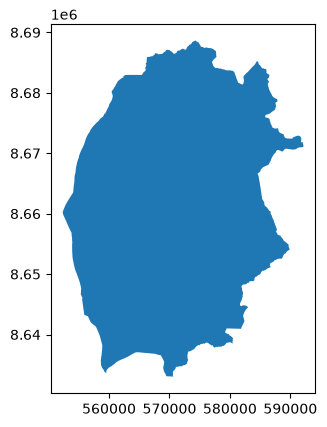

In [28]:
TA_boundary.plot()

<Axes: >

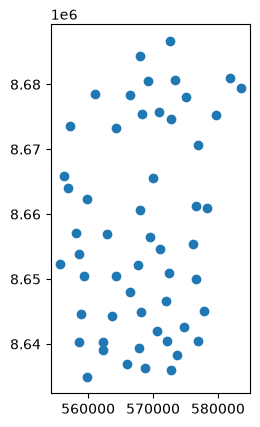

In [29]:
#plotting primary_schools
primary_schools.plot()

<Axes: >

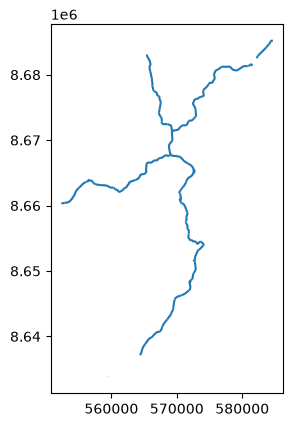

In [30]:
# plotting the main_roads
main_roads.plot()

<Axes: >

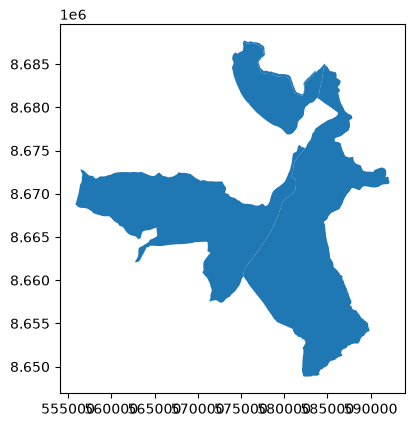

In [31]:
# plotting the protected_areas 
protected_areas.plot()

In this step, buffers are created around existing primary schools and main roads to represent the distance requirements for selecting suitable sites for new primary schools. A 2,000-meters buffer is created around existing primary schools to identify areas where new schools should not be located, while a 500-meters buffer is created around main roads to identify areas that meet the road-accessibility criterion.

The buffer zones are plotted to visualise their spatial distribution and relationship with the study area. This helps identify areas that fall within the required distances and supports the subsequent overlay analysis to determine suitable locations for new primary schools.

In [32]:
# Create a 2000m buffer around primary schools
primary_schools_buff = primary_schools.copy()
primary_schools_buff["geometry"] = primary_schools_buff.buffer(2000)

<Axes: >

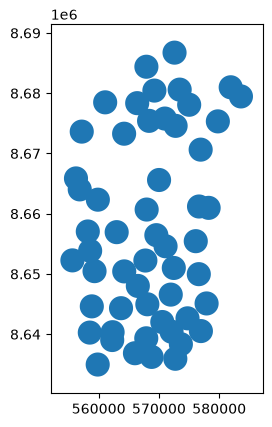

In [33]:
# Plot the primary_schools_buff
primary_schools_buff.plot()

In [34]:
# Create a 500m buffer around main roads 
main_roads_buff = main_roads.copy()
main_roads_buff["geometry"] = main_roads_buff.buffer(500)

<Axes: >

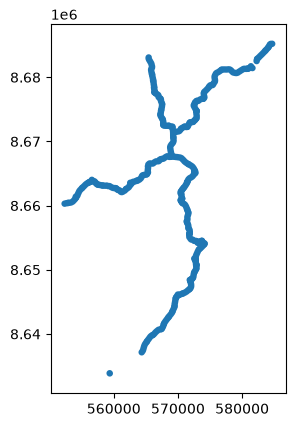

In [35]:
# Plot the main_roads_buff
main_roads_buff.plot()

In this step, the protected areas dataset is prepared for use in the suitability analysis. A copy of the protected areas layer is created to preserve the original dataset while allowing further spatial processing. Unlike the primary school and main road layers, protected areas do not require buffering because the Ministry of Education specifies that new primary schools must not be located within protected areas.

The protected areas are then plotted to visualise their spatial distribution in relation to the TA Mzikubola study area. This helps identify areas restricted from school construction and supports their exclusion during the subsequent overlay analysis.

In [36]:
# Prepare the protected areas
protected_areas_exclusion = protected_areas.copy()


<Axes: >

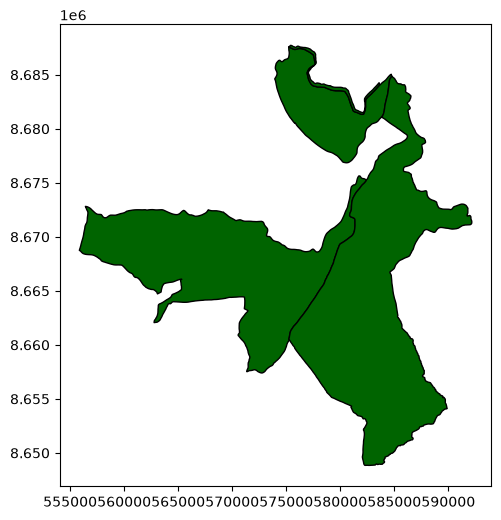

In [37]:
# plotting the protected_ areas_exclusion
protected_areas_exclusion.plot(
    color="darkgreen",
    edgecolor="black",
    figsize=(6, 6)
)

In this step, the 2,000-meter buffers around existing primary schools and the 500-meters buffers around main roads are plotted together with the protected areas. Different colours are used to distinguish the layers: green represents protected areas, red represents main road buffers, and orange represents primary school buffers.

Visualising these layers together helps identify areas that are restricted because of their proximity to existing schools or their location within protected areas, as well as areas that meet the road-accessibility requirement. This provides an overview of the spatial criteria before performing the final overlay analysis to identify suitable locations for new primary schools.

<Axes: >

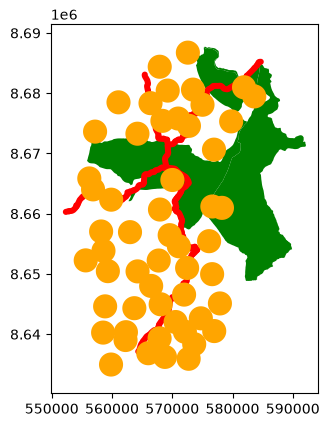

In [38]:
#plot all the buffers
ax = protected_areas_exclusion.plot(facecolor = "green")
main_roads_buff.plot(ax = ax, facecolor = "red")
primary_schools_buff.plot(ax = ax, facecolor = "orange")

In this step, spatial overlay operations are performed to identify areas that satisfy all three school site selection criteria. First, the main road buffer is intersected with the TA Mzikubola boundary to retain areas that lie within the study area and are no more than 500 meters from main roads.

Next, areas within 2 kilometres of existing primary schools are removed because new schools must be at least 2 kilometres away from existing schools. Finally, protected areas are excluded to ensure that the remaining land does not overlap with restricted conservation areas.

The resulting desired_areas layer represents the potential locations that meet the specified spatial criteria for constructing new primary schools in TA Mzikubola.

In [39]:
# Identify areas within 500 m of main roads
merged = main_roads_buff.overlay(TA_boundary, how="intersection")

# Removing areas within 2 km of existing primary schools
areas_after_schools = merged.overlay(
    primary_schools_buff, how="difference"
)

# Removing protected areas
desired_areas = areas_after_schools.overlay(
    protected_areas, how="difference"
)

The suitable areas identified through the spatial overlay analysis are plotted to visualise their spatial distribution within TA Mzikubola, Mzimba District. The plot displays the remaining areas that satisfy the three site selection criteria: being at least 2 km away from existing primary schools, within 500 m of main roads, and outside protected areas. This visualisation helps identify potential locations for constructing new primary schools.

<Axes: >

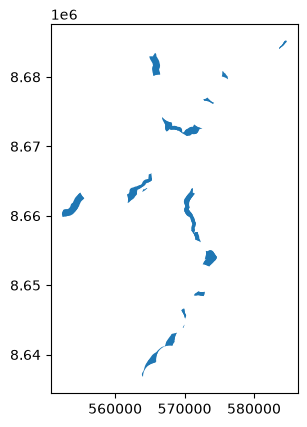

In [40]:
# Plot the suitable areas
desired_areas.plot()

In this step, the dissolve() function is used to combine the geometries of the suitable areas into a single spatial feature, removing internal boundaries between adjacent suitable polygons. This simplifies the final output and provides a clearer representation of the land that meets all three school site selection criteria.

The dissolved suitable areas are then plotted to visualise the overall distribution of potential sites for new primary schools within TA Mzikubola, Mzimba District.

<Axes: >

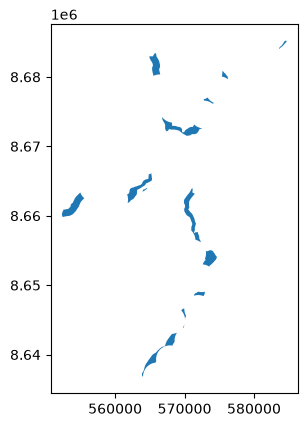

In [41]:
suitable_areas = desired_areas[["geometry"]].dissolve()
# Plot suitable areas 
suitable_areas.plot()

In [43]:
# Calculate the total suitable area in square metres
total_area_m2 = suitable_areas.area.sum()

# Convert the total area into hectares and square kilometres
total_area_ha = total_area_m2 / 10_000
total_area_km2 = total_area_m2 / 1_000_000

# Display the results
print(f"Total suitable area: {total_area_km2:.2f} km²")
print(f"Total suitable area: {total_area_ha:.2f} hectares")

Total suitable area: 28.51 km²
Total suitable area: 2851.31 hectares


Displaying the Suitable Areas

This step displays the suitable locations for new primary schools on an interactive map.

In [44]:
m = suitable_areas.explore()

TA_boundary.explore(
    m=m,
    color="black",
    style_kwds={"fill": False, "weight": 3},
    name="TA Mazikumbola boundary"
)
m

In [46]:
%pip install matplotlib-scalebar

Note: you may need to restart the kernel to use updated packages.


The prepared spatial layers were visualised using Matplotlib, with suitable areas shown in orange, protected areas in green, main roads in red, existing primary schools in blue, and the TA Mzikubola boundary in black. The map includes a title, legend, north arrow, scale bar, data sources and coordinate reference system. The final map was exported as PNG and PDF files to the outputs folder.

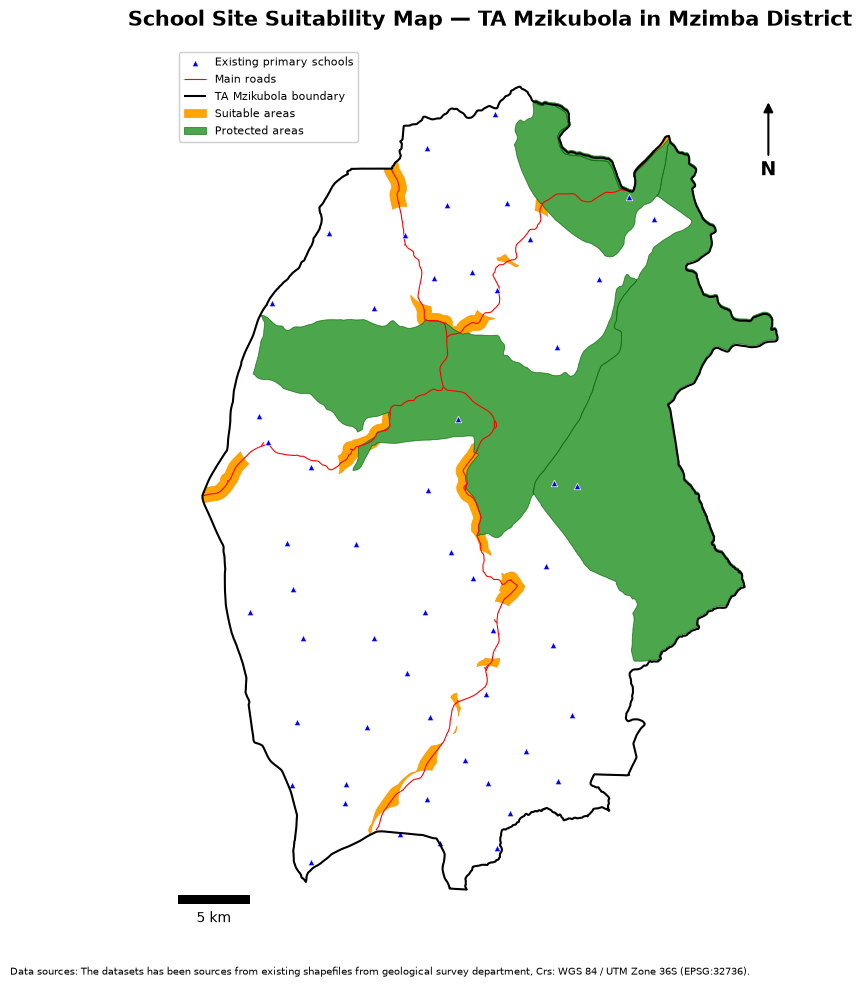

In [50]:
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar
from pathlib import Path

# Point to the existing outputs folder in the main project directory
output_dir = Path("../outputs")

# Create figure
fig, ax = plt.subplots(figsize=(10, 10))

# 1. Plot suitable areas in orange
suitable_areas.plot(
    ax=ax,
    color="orange",
    edgecolor="darkorange",
    linewidth=0.4,
    label="Suitable areas",
    zorder=1
)

# 2. Plot protected areas in green
protected_areas.plot(
    ax=ax,
    color="green",
    edgecolor="darkgreen",
    linewidth=0.6,
    alpha=0.7,
    label="Protected areas",
    zorder=2
)

# 3. Plot main roads in red
main_roads.plot(
    ax=ax,
    color="red",
    linewidth=0.8,
    label="Main roads",
    zorder=3
)

# 4. Plot existing primary schools in blue
primary_schools.plot(
    ax=ax,
    color="blue",
    markersize=22,
    marker="^",
    edgecolor="white",
    linewidth=0.5,
    label="Existing primary schools",
    zorder=4
)

# 5. Plot TA boundary in black
TA_boundary.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5,
    label="TA Mzikubola boundary",
    zorder=5
)

# Add map title
ax.set_title(
    "School Site Suitability Map — TA Mzikubola in Mzimba District",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Add scale bar (CRS units are metres)
ax.add_artist(
    ScaleBar(
        1,
        units="m",
        location="lower left",
        box_alpha=0.8
    )
)

# Add north arrow
ax.annotate(
    "N",
    xy=(0.94, 0.94),
    xytext=(0.94, 0.86),
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-|>",
        color="black",
        lw=1.5
    )
)

# Add legend in the required order
handles, labels = ax.get_legend_handles_labels()

legend_order = [
    "Existing primary schools",
    "Main roads",
    "TA Mzikubola boundary",
    "Suitable areas",
    "Protected areas"
]

ordered_handles = [
    handles[labels.index(label)]
    for label in legend_order
]

ax.legend(
    ordered_handles,
    legend_order,
    loc="upper left",
    fontsize=8,
    frameon=True,
    framealpha=0.95
)
# Remove axis ticks and labels
ax.set_axis_off()

# Add data sources and coordinate reference system
fig.text(
    0.02,
    0.02,
    "Data sources: The datasets has been sources from existing shapefiles from geological survey department, "
    "Crs: WGS 84 / UTM Zone 36S "
    "(EPSG:32736).",
    fontsize=7,
    wrap=True
)

# Adjust layout
plt.tight_layout(rect=[0, 0.05, 1, 1])

# Save static map as PNG
fig.savefig(
    output_dir / "mzikubola_school_suitability.png",
    dpi=300,
    bbox_inches="tight"
)

# Save static map as PDF
fig.savefig(
    output_dir / "mzikubola_school_suitability.pdf",
    dpi=300,
    bbox_inches="tight"
)

In [51]:
%pip install folium

Note: you may need to restart the kernel to use updated packages.


The interactive map was created using Folium, with all spatial datasets reprojected to WGS 84 (EPSG:4326) for web mapping. The map displays satellite imagery as the basemap, alongside the TA Mzikubola boundary, suitable areas, protected areas, main roads, and existing primary schools. Layer controls and a measurement tool were added to support interactive exploration. Finally, the map was saved as an HTML file in the outputs folder.

In [58]:

import folium
from folium import plugins
from pathlib import Path

# point out the output path 
output_dir = Path("../outputs")

# Use WGS84 coordinates for the web map
ta_web = TA_boundary.to_crs(epsg=4326)
roads_web = main_roads.to_crs(epsg=4326)
schools_web = primary_schools.to_crs(epsg=4326)
protected_web = protected_areas.to_crs(epsg=4326)
suitable_web = suitable_areas.to_crs(epsg=4326)

# Centre map on TA boundary
centre = ta_web.geometry.union_all().centroid

# Get the latitude and longitude of the TA boundary centre
latitude = centre.y
longitude = centre.x

# Create the interactive map
m = folium.Map(
    location=[latitude, longitude],
    zoom_start=12,
    tiles=None
)

# Add satellite imagery basemap
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery",
    name="Satellite Imagery",
    overlay=False,
    control=True
).add_to(m)

# TA boundary layer
folium.GeoJson(
    ta_web,
    name="TA Mzikubola boundary",
    style_function=lambda feature: {
        "color": "black",
        "weight": 2,
        "fillOpacity": 0
    },
    tooltip="TA Mzikubola"
).add_to(m)

# Suitable areas
folium.GeoJson(
    suitable_web,
    name="Suitable areas",
    style_function=lambda feature: {
        "fillColor": "#66cc66",
        "color": "darkgreen",
        "weight": 1,
        "fillOpacity": 0.55
    },
    tooltip="Suitable land for new primary schools"
).add_to(m)

# Protected areas
folium.GeoJson(
    protected_web,
    name="Protected areas",
    style_function=lambda feature: {
        "fillColor": "grey",
        "color": "black",
        "weight": 1,
        "fillOpacity": 0.6
    },
    tooltip="Protected area"
).add_to(m)

# Main roads
folium.GeoJson(
    roads_web,
    name="Main roads",
    style_function=lambda feature: {
        "color": "orange",
        "weight": 2
    },
    tooltip="Main road"
).add_to(m)

# Existing schools
school_layer = folium.FeatureGroup(
    name="Existing primary schools"
)

for _, row in schools_web.iterrows():
    point = row.geometry
    if point.geom_type == "Point":
        folium.Marker(
            location=[point.y, point.x],
            tooltip="Existing primary school",
            popup=folium.Popup(
                f"School attributes: {row.drop(labels='geometry').to_dict()}",
                max_width=300
            ),
            icon=folium.Icon(color="red", icon="education", prefix="fa")
        ).add_to(school_layer)

school_layer.add_to(m)

# Layer controls and optional measurement tool
folium.LayerControl(collapsed=False).add_to(m)
plugins.MeasureControl().add_to(m)

# Save as a standalone HTML file
m.save(output_dir / "mzikubola_school_suitability.html")

print("Interactive map saved successfully.")



Interactive map saved successfully.
